In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

folder = "/content/drive/MyDrive/"

print(os.listdir(folder))

['Карта без названия.gmap', 'Willingen 2012', 'CRD', 'Colab Notebooks', 'face_project', 'IMDB Dataset (2).csv', 'IMDb_results']


In [3]:
import pandas as pd
import os

DATA_PATH = "/content/drive/MyDrive/IMDB Dataset (2).csv"

df = pd.read_csv(DATA_PATH)

print("Размер датасета:", df.shape)
print("\nСтолбцы:", df.columns.tolist())
print("\nПропуски:\n", df.isnull().sum())
print("\nКлассы:\n", df.iloc[:, 1].value_counts())
display(df.head())

Размер датасета: (50000, 2)

Столбцы: ['review', 'sentiment']

Пропуски:
 review       0
sentiment    0
dtype: int64

Классы:
 sentiment
positive    25000
negative    25000
Name: count, dtype: int64


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:

# ============================================================
# 1. Импорты и конфигурация
# ============================================================
import os
import re
import html
import json
import math
import random
import time
import gc

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import transformers
import sklearn

from tqdm.auto import tqdm
from torch.utils.data import Dataset, Subset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_fscore_support,
    roc_auc_score,
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding,
    TrainerCallback,
    set_seed,
)

# ----- Google Drive -----
from google.colab import drive
drive.mount("/content/drive")

# ----- Пути -----
DRIVE_DIR = "/content/drive/MyDrive/IMDb_results"
CSV_PATH = "/content/drive/MyDrive/IMDB Dataset (2).csv"

REPORT_DIR = f"{DRIVE_DIR}/reports"
MODEL_DIR = f"{DRIVE_DIR}/distilbert_imdb_final"
BASELINE_PATH = f"{DRIVE_DIR}/tfidf_svc_baseline.joblib"

# Чекпойнты обучения храним локально в Colab:
# это обычно быстрее, чем постоянно писать их на Drive.
OUTPUT_DIR = "/content/distilbert_imdb"

os.makedirs(REPORT_DIR, exist_ok=True)
os.makedirs(DRIVE_DIR, exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.20
VAL_SIZE_WITHIN_TRAINVAL = 0.125
MAX_FEATURES = 50_000
SVC_C = 0.5

# ----- DistilBERT -----
MODEL_NAME = "distilbert-base-uncased"
MAX_LEN = 512
BATCH_SIZE = 8
GRAD_ACCUM = 4
EPOCHS = 2
LR = 2e-5

# ----- GPU и precision -----
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

USE_BF16 = (
    torch.cuda.is_available()
    and torch.cuda.is_bf16_supported()
)
USE_FP16 = torch.cuda.is_available() and not USE_BF16

print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1e9,
            2
        ),
        "GB"
    )

print("BF16:", USE_BF16)
print("FP16:", USE_FP16)
print("Effective batch size:", BATCH_SIZE * GRAD_ACCUM)

# При необходимости можно дополнительно включить:
# torch.use_deterministic_algorithms(True)
# Это может замедлить обучение или вызвать ошибки
# для операций без детерминированной реализации.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
GPU: Tesla T4
VRAM: 15.64 GB
BF16: True
FP16: False
Effective batch size: 32


In [5]:
import torch

print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3, 2
        ),
        "GB"
    )

CUDA: True
GPU: Tesla T4
VRAM: 14.56 GB


In [6]:

# ============================================================
# 2. Загрузка и очистка данных
# ============================================================
def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<br\s*/?>", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


df = pd.read_csv(CSV_PATH)

required_columns = {"review", "sentiment"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"В CSV отсутствуют обязательные столбцы: {missing_columns}"
    )

df = df.dropna(subset=["review", "sentiment"]).copy()

df["sentiment"] = (
    df["sentiment"].astype(str).str.strip().str.lower()
)

df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1,
})

# Удаляем неизвестные метки
df = df.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype("int64")

df["review_clean"] = df["review"].apply(clean_text)

# Удаляем пустые отзывы
df = df[df["review_clean"].str.len() > 0].copy()
df = df.reset_index(drop=True)

if df.empty:
    raise ValueError("После очистки датасет оказался пустым.")

if df["label"].nunique() != 2:
    raise ValueError("Для обучения необходимы оба класса: 0 и 1.")

print(f"Всего примеров после очистки: {len(df):,}")
print("\nРаспределение классов:")
print(df["label"].value_counts().sort_index())

print("\nДоли классов:")
print(df["label"].value_counts(normalize=True).sort_index().round(4))


Всего примеров после очистки: 50,000

Распределение классов:
label
0    25000
1    25000
Name: count, dtype: int64

Доли классов:
label
0    0.5
1    0.5
Name: proportion, dtype: float64


In [7]:

# ============================================================
# 3. Train / Validation / Test
# ============================================================
X_trainval, X_test, y_trainval, y_test = train_test_split(
    df["review_clean"],
    df["label"],
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=df["label"],
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=VAL_SIZE_WITHIN_TRAINVAL,
    random_state=RANDOM_STATE,
    stratify=y_trainval,
)

# Индексы и порядок строк не должны нарушать соответствие текстов и меток
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

print(
    f"Train:      {len(X_train):,} "
    f"({len(X_train) / len(df):.1%})"
)
print(
    f"Validation: {len(X_val):,} "
    f"({len(X_val) / len(df):.1%})"
)
print(
    f"Test:       {len(X_test):,} "
    f"({len(X_test) / len(df):.1%})"
)

print("\nБаланс классов:")
print("Train:", y_train.value_counts().sort_index().to_dict())
print("Val:  ", y_val.value_counts().sort_index().to_dict())
print("Test: ", y_test.value_counts().sort_index().to_dict())


Train:      35,000 (70.0%)
Validation: 5,000 (10.0%)
Test:       10,000 (20.0%)

Баланс классов:
Train: {0: 17500, 1: 17500}
Val:   {0: 2500, 1: 2500}
Test:  {0: 5000, 1: 5000}


In [8]:

# ============================================================
# 4. Baseline: TF-IDF + LinearSVC
# ============================================================
import joblib

baseline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            stop_words="english",
            max_features=MAX_FEATURES,
            dtype=np.float32,
        ),
    ),
    ("clf", LinearSVC(C=SVC_C, random_state=RANDOM_STATE)),
])

start_time = time.time()
baseline.fit(X_train, y_train)
baseline_train_seconds = time.time() - start_time

# Validation — диагностическая оценка
y_val_baseline = baseline.predict(X_val)
val_baseline_acc = accuracy_score(y_val, y_val_baseline)

print(f"Baseline training time: {baseline_train_seconds:.1f} sec")
print(f"Baseline validation accuracy: {val_baseline_acc:.4f}")

# Сохраняем обученный baseline
joblib.dump(baseline, BASELINE_PATH)

print(f"Baseline сохранён: {BASELINE_PATH}")


Baseline training time: 29.5 sec
Baseline validation accuracy: 0.8992
Baseline сохранён: /content/drive/MyDrive/IMDb_results/tfidf_svc_baseline.joblib


In [9]:

# ============================================================
# 5. Токенизация
# ============================================================
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def tokenize_texts(texts, tokenizer, max_len):
    """Токенизация, совместимая с Transformers 5.x."""
    return tokenizer(
        list(texts),
        add_special_tokens=True,
        truncation=True,
        max_length=max_len,
        padding=False,
        return_attention_mask=True,
    )


train_enc = tokenize_texts(X_train.tolist(), tokenizer, MAX_LEN)
val_enc = tokenize_texts(X_val.tolist(), tokenizer, MAX_LEN)
test_enc = tokenize_texts(X_test.tolist(), tokenizer, MAX_LEN)

print("Токенизация завершена.")
print("Train:", len(train_enc["input_ids"]))
print("Validation:", len(val_enc["input_ids"]))
print("Test:", len(test_enc["input_ids"]))

assert max(map(len, train_enc["input_ids"])) <= MAX_LEN
assert max(map(len, val_enc["input_ids"])) <= MAX_LEN
assert max(map(len, test_enc["input_ids"])) <= MAX_LEN


train_lengths = [len(x) for x in train_enc["input_ids"]]

print("Длина токенизированных отзывов:")
print(f"Min:    {min(train_lengths)}")
print(f"Median: {np.median(train_lengths):.0f}")
print(f"Mean:   {np.mean(train_lengths):.1f}")
print(f"Max:    {max(train_lengths)}")


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Токенизация завершена.
Train: 35000
Validation: 5000
Test: 10000
Длина токенизированных отзывов:
Min:    11
Median: 221
Mean:   263.1
Max:    512


In [10]:

# ============================================================
# 6. PyTorch Dataset
# ============================================================
class IMDbDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = list(labels)

        if len(self.labels) != len(self.encodings["input_ids"]):
            raise ValueError("Число текстов и меток не совпадает.")

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(value[idx], dtype=torch.long)
            for key, value in self.encodings.items()
        }
        item["labels"] = torch.tensor(
            int(self.labels[idx]), dtype=torch.long
        )
        return item


train_ds = IMDbDataset(train_enc, y_train.tolist())
val_ds = IMDbDataset(val_enc, y_val.tolist())
test_ds = IMDbDataset(test_enc, y_test.tolist())

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    pad_to_multiple_of=8 if DEVICE == "cuda" else None,
)

print(f"train_ds: {len(train_ds):,}")
print(f"val_ds:   {len(val_ds):,}")
print(f"test_ds:  {len(test_ds):,}")


# ============================================================
# 7. Метрики для Trainer
# ============================================================
def compute_metrics(eval_pred):
    logits = eval_pred.predictions
    labels = eval_pred.label_ids

    if isinstance(logits, tuple):
        logits = logits[0]

    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, preds),
    }


train_ds: 35,000
val_ds:   5,000
test_ds:  10,000


In [11]:

# ============================================================
# 8. Progress callback
# ============================================================
class ProgressCallback(TrainerCallback):
    def __init__(self, desc="DistilBERT"):
        self.desc = desc
        self.bar = None
        self.start_time = None
        self.last_step = 0

    def on_train_begin(self, args, state, control, **kwargs):
        self.start_time = time.time()
        self.last_step = state.global_step

        total = (
            state.max_steps
            if state.max_steps is not None and state.max_steps > 0
            else None
        )

        self.bar = tqdm(
            total=total,
            initial=state.global_step,
            desc=self.desc,
            unit="step",
            dynamic_ncols=True,
        )

    def on_step_end(self, args, state, control, **kwargs):
        if self.bar is None:
            return

        delta = state.global_step - self.last_step

        if delta > 0:
            self.bar.update(delta)
            self.last_step = state.global_step

        elapsed = time.time() - self.start_time
        loss = next(
            (
                entry["loss"]
                for entry in reversed(state.log_history)
                if "loss" in entry
            ),
            None,
        )

        eta = None
        if state.max_steps and state.global_step > 0:
            eta = (
                elapsed / state.global_step
                * max(0, state.max_steps - state.global_step)
            )

        postfix = {}
        if loss is not None:
            postfix["loss"] = f"{loss:.4f}"
        if eta is not None:
            postfix["ETA"] = f"{eta / 60:.1f} min"

        self.bar.set_postfix(postfix)

    def on_train_end(self, args, state, control, **kwargs):
        if self.bar is not None:
            self.bar.close()
            self.bar = None


In [12]:

# ============================================================
# 9. Smoke-test: короткая проверка обучения DistilBERT
# ============================================================

import torch
import numpy as np

from torch.utils.data import Subset
from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
)

# Небольшие подмножества для проверки
SMOKE_SIZE = 256
SMOKE_VAL_SIZE = 128

smoke_train_ds = Subset(
    train_ds,
    range(min(SMOKE_SIZE, len(train_ds)))
)

smoke_val_ds = Subset(
    val_ds,
    range(min(SMOKE_VAL_SIZE, len(val_ds)))
)

print("Smoke train:", len(smoke_train_ds))
print("Smoke validation:", len(smoke_val_ds))

# Отдельная свежая модель
smoke_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "negative", 1: "positive"},
    label2id={"negative": 0, "positive": 1},
)

# Динамический padding: выравниваем длины внутри каждого батча
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True,
    pad_to_multiple_of=8 if torch.cuda.is_available() else None,
    return_tensors="pt",
)

smoke_args = TrainingArguments(
    output_dir="./smoke_check",

    num_train_epochs=1,

    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=1,

    learning_rate=1e-5,
    warmup_steps=0,
    weight_decay=0.01,

    # На небольшой VRAM сначала проверяем обучение без FP16
    fp16=False,

    eval_strategy="epoch",
    save_strategy="no",

    logging_strategy="steps",
    logging_steps=10,

    report_to="none",
    disable_tqdm=True,
    dataloader_num_workers=0,

    seed=RANDOM_STATE,
    data_seed=RANDOM_STATE,
)

smoke_trainer = Trainer(
    model=smoke_model,
    args=smoke_args,
    train_dataset=smoke_train_ds,
    eval_dataset=smoke_val_ds,
    data_collator=data_collator,
)

# Оценка на обучающих примерах до обучения
initial_metrics = smoke_trainer.evaluate(
    eval_dataset=smoke_train_ds,
    metric_key_prefix="before",
)

print(
    "Loss до обучения:",
    initial_metrics["before_loss"],
)

# Короткое обучение
smoke_trainer.train()

# Оценка на тех же обучающих примерах после обучения
final_metrics = smoke_trainer.evaluate(
    eval_dataset=smoke_train_ds,
    metric_key_prefix="after",
)

print(
    "Loss после обучения:",
    final_metrics["after_loss"],
)

# Проверка на отдельной validation-выборке
val_metrics = smoke_trainer.evaluate(
    eval_dataset=smoke_val_ds,
    metric_key_prefix="smoke_val",
)

print("Validation после обучения:", val_metrics)


Smoke train: 256
Smoke validation: 128


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'before_loss': '0.6948', 'before_model_preparation_time': '0.0017', 'before_runtime': '4.002', 'before_samples_per_second': '63.97', 'before_steps_per_second': '31.99', 'epoch': 0}
Loss до обучения: 0.694824755191803
{'loss': '0.6835', 'grad_norm': '5.064', 'learning_rate': '9.297e-06', 'epoch': '0.07812'}
{'loss': '0.7294', 'grad_norm': '4.703', 'learning_rate': '8.516e-06', 'epoch': '0.1562'}
{'loss': '0.6981', 'grad_norm': '5.535', 'learning_rate': '7.734e-06', 'epoch': '0.2344'}
{'loss': '0.7144', 'grad_norm': '2.143', 'learning_rate': '6.953e-06', 'epoch': '0.3125'}
{'loss': '0.668', 'grad_norm': '4.721', 'learning_rate': '6.172e-06', 'epoch': '0.3906'}
{'loss': '0.6778', 'grad_norm': '5.017', 'learning_rate': '5.391e-06', 'epoch': '0.4688'}
{'loss': '0.6811', 'grad_norm': '5.594', 'learning_rate': '4.609e-06', 'epoch': '0.5469'}
{'loss': '0.6759', 'grad_norm': '5.467', 'learning_rate': '3.828e-06', 'epoch': '0.625'}
{'loss': '0.6751', 'grad_norm': '2.302', 'learning_rate': '3.04

In [13]:

# ============================================================
# 10. Загружаем свежую основную модель
# ============================================================

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "negative", 1: "positive"},
    label2id={"negative": 0, "positive": 1},
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print(f"Параметров в модели: {model.num_parameters():,}")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Device: cuda
Параметров в модели: 66,955,010


In [14]:

# ============================================================
# 11. TrainingArguments
# ============================================================

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LR,
    warmup_steps=0,
    weight_decay=0.01,
    fp16=USE_FP16,
    bf16=USE_BF16,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
    logging_strategy="steps",
    logging_steps=50,
    report_to="none",
    disable_tqdm=True,
    seed=RANDOM_STATE,
    data_seed=RANDOM_STATE,
    dataloader_num_workers=2,
)


In [15]:

# ============================================================
# 12. Trainer для полного обучения
# ============================================================

trainer = Trainer(
    model=model,
    args=training_args,

    train_dataset=train_ds,
    eval_dataset=val_ds,

    data_collator=data_collator,

    compute_metrics=compute_metrics,

    callbacks=[
        ProgressCallback("DistilBERT training")
    ],
)

print("Основной Trainer создан.")
print("Обучение пока не запущено.")


Основной Trainer создан.
Обучение пока не запущено.


In [16]:
# ============================================================
# 13. Обучение
# ============================================================
start_time = time.time()

train_result = trainer.train()

training_seconds = time.time() - start_time

print(f"\nTraining time: {training_seconds / 60:.2f} min")
print(f"Best checkpoint: {trainer.state.best_model_checkpoint}")
print(f"Best validation metric: {trainer.state.best_metric}")

print("\nИтоговые training metrics:")
print(train_result.metrics)


DistilBERT training:   0%|          | 0/2188 [00:00<?, ?step/s]

{'loss': '2.333', 'grad_norm': '12.9', 'learning_rate': '1.955e-05', 'epoch': '0.04571'}
{'loss': '1.252', 'grad_norm': '32.52', 'learning_rate': '1.91e-05', 'epoch': '0.09143'}
{'loss': '1.097', 'grad_norm': '14.83', 'learning_rate': '1.864e-05', 'epoch': '0.1371'}
{'loss': '1.085', 'grad_norm': '36.95', 'learning_rate': '1.818e-05', 'epoch': '0.1829'}
{'loss': '0.9998', 'grad_norm': '13.65', 'learning_rate': '1.772e-05', 'epoch': '0.2286'}
{'loss': '0.9141', 'grad_norm': '21.75', 'learning_rate': '1.727e-05', 'epoch': '0.2743'}
{'loss': '0.9203', 'grad_norm': '15.69', 'learning_rate': '1.681e-05', 'epoch': '0.32'}
{'loss': '0.881', 'grad_norm': '12.17', 'learning_rate': '1.635e-05', 'epoch': '0.3657'}
{'loss': '1.01', 'grad_norm': '28.31', 'learning_rate': '1.59e-05', 'epoch': '0.4114'}
{'loss': '0.8753', 'grad_norm': '25.9', 'learning_rate': '1.544e-05', 'epoch': '0.4571'}
{'loss': '0.8567', 'grad_norm': '16.07', 'learning_rate': '1.498e-05', 'epoch': '0.5029'}
{'loss': '0.8496', 'g

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.8407', 'grad_norm': '24.45', 'learning_rate': '9.954e-06', 'epoch': '1.005'}
{'loss': '0.5288', 'grad_norm': '30.78', 'learning_rate': '9.497e-06', 'epoch': '1.051'}
{'loss': '0.5063', 'grad_norm': '34.21', 'learning_rate': '9.04e-06', 'epoch': '1.097'}
{'loss': '0.6422', 'grad_norm': '17.74', 'learning_rate': '8.583e-06', 'epoch': '1.143'}
{'loss': '0.529', 'grad_norm': '14.27', 'learning_rate': '8.126e-06', 'epoch': '1.188'}
{'loss': '0.6476', 'grad_norm': '8.748', 'learning_rate': '7.669e-06', 'epoch': '1.234'}
{'loss': '0.6086', 'grad_norm': '33.57', 'learning_rate': '7.212e-06', 'epoch': '1.28'}
{'loss': '0.4679', 'grad_norm': '16.46', 'learning_rate': '6.755e-06', 'epoch': '1.325'}
{'loss': '0.5764', 'grad_norm': '28.07', 'learning_rate': '6.298e-06', 'epoch': '1.371'}
{'loss': '0.6269', 'grad_norm': '36.62', 'learning_rate': '5.841e-06', 'epoch': '1.417'}
{'loss': '0.4252', 'grad_norm': '26.94', 'learning_rate': '5.384e-06', 'epoch': '1.463'}
{'loss': '0.5416', 'grad

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '4612', 'train_samples_per_second': '15.18', 'train_steps_per_second': '0.474', 'train_loss': '0.7558', 'epoch': '2'}

Training time: 76.88 min
Best checkpoint: /content/distilbert_imdb/checkpoint-2188
Best validation metric: 0.9342

Итоговые training metrics:
{'train_runtime': 4611.791, 'train_samples_per_second': 15.178, 'train_steps_per_second': 0.474, 'train_loss': 0.7557892346077035, 'epoch': 2.0}


In [17]:

# ============================================================
# 14. Финальная оценка DistilBERT
# ============================================================
# Один проход по тестовой выборке:
pred_output = trainer.predict(
    test_ds,
    metric_key_prefix="test",
)

test_results = pred_output.metrics
print(test_results)

bert_logits = pred_output.predictions

if isinstance(bert_logits, tuple):
    bert_logits = bert_logits[0]

y_pred_bert = np.argmax(bert_logits, axis=-1)

bert_probs = torch.softmax(
    torch.tensor(bert_logits, dtype=torch.float32),
    dim=-1,
).numpy()

bert_proba_pos = bert_probs[:, 1]


# ============================================================
# 15. Финальная оценка baseline на том же test
# ============================================================
y_pred_baseline = baseline.predict(X_test)

# LinearSVC не выдаёт вероятности по умолчанию.
# Для ROC-AUC используем decision_function.
baseline_scores = baseline.decision_function(X_test)


# ============================================================
# 16. Сводка метрик
# ============================================================
def metrics_dict(y_true, y_pred, scores):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0,
    )

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1,
        "roc_auc": roc_auc_score(y_true, scores),
    }


baseline_metrics = metrics_dict(
    y_test, y_pred_baseline, baseline_scores
)

bert_metrics = metrics_dict(
    y_test, y_pred_bert, bert_proba_pos
)

metrics_df = pd.DataFrame({
    "Baseline (TF-IDF + LinearSVC)": baseline_metrics,
    "DistilBERT (fine-tuned)": bert_metrics,
}).T

metrics_df = metrics_df.round(4)

print("\n" + "=" * 65)
print("ИТОГОВОЕ СРАВНЕНИЕ НА TEST")
print("=" * 65)
print(metrics_df)
print("=" * 65)

print(
    f"\nРазница accuracy: "
    f"{(bert_metrics['accuracy'] - baseline_metrics['accuracy']) * 100:+.2f} п.п."
)

print("\nClassification report — Baseline:")
print(classification_report(
    y_test,
    y_pred_baseline,
    labels=[0, 1],
    target_names=["negative", "positive"],
    zero_division=0,
))

print("\nClassification report — DistilBERT:")
print(classification_report(
    y_test,
    y_pred_bert,
    labels=[0, 1],
    target_names=["negative", "positive"],
    zero_division=0,
))


{'test_loss': 0.1852845996618271, 'test_accuracy': 0.9377, 'test_runtime': 233.8951, 'test_samples_per_second': 42.754, 'test_steps_per_second': 2.672}

ИТОГОВОЕ СРАВНЕНИЕ НА TEST
                               accuracy  precision_macro  recall_macro  \
Baseline (TF-IDF + LinearSVC)    0.9064           0.9065        0.9064   
DistilBERT (fine-tuned)          0.9377           0.9377        0.9377   

                               f1_macro  roc_auc  
Baseline (TF-IDF + LinearSVC)    0.9064   0.9662  
DistilBERT (fine-tuned)          0.9377   0.9831  

Разница accuracy: +3.13 п.п.

Classification report — Baseline:
              precision    recall  f1-score   support

    negative       0.91      0.90      0.91      5000
    positive       0.90      0.91      0.91      5000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000


Classification report — DistilBERT:
              p

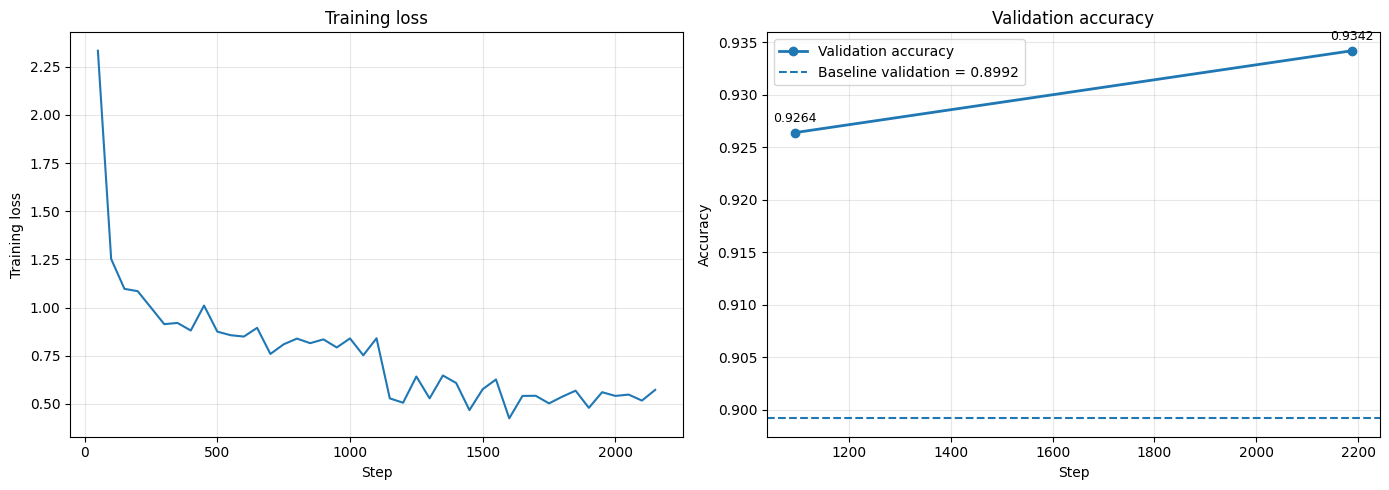

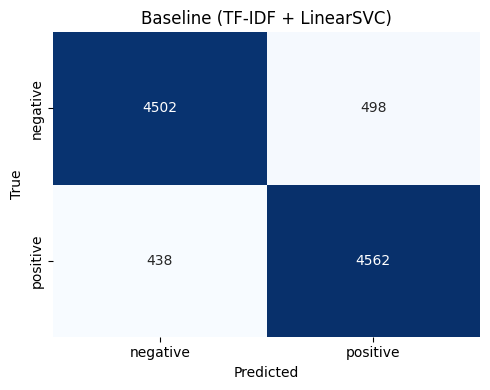

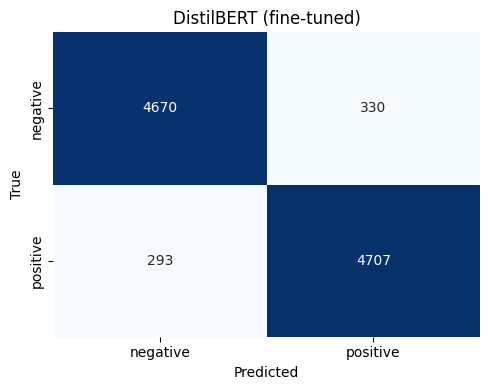

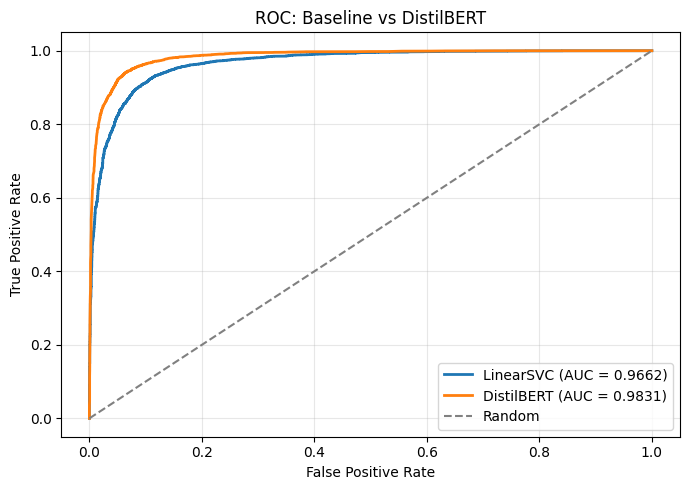

Baseline ROC-AUC: 0.9662
DistilBERT ROC-AUC: 0.9831


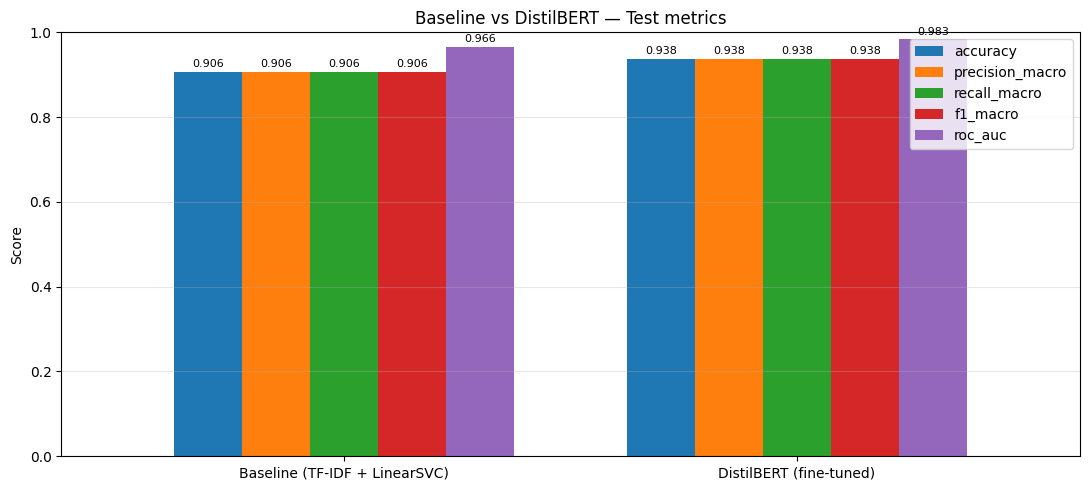

In [18]:

# ============================================================
# 17. График истории обучения
# ============================================================
def plot_training_history(trainer, baseline_acc=None, save_path=None):
    history = trainer.state.log_history

    train_logs = [
        x for x in history
        if "loss" in x and "eval_accuracy" not in x
    ]

    # Во время обучения eval_accuracy относится к validation.
    # Финальные test-метрики имеют префикс test_.
    val_logs = [
        x for x in history
        if "eval_accuracy" in x
    ]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    if train_logs:
        axes[0].plot(
            [x["step"] for x in train_logs],
            [x["loss"] for x in train_logs],
            linewidth=1.5,
        )
    else:
        axes[0].text(
            0.5, 0.5, "No training loss logs",
            ha="center", va="center",
            transform=axes[0].transAxes,
        )

    axes[0].set_xlabel("Step")
    axes[0].set_ylabel("Training loss")
    axes[0].set_title("Training loss")
    axes[0].grid(alpha=0.3)

    if val_logs:
        val_steps = [x["step"] for x in val_logs]
        val_accs = [x["eval_accuracy"] for x in val_logs]

        axes[1].plot(
            val_steps,
            val_accs,
            marker="o",
            linewidth=2,
            label="Validation accuracy",
        )

        for step, acc in zip(val_steps, val_accs):
            axes[1].annotate(
                f"{acc:.4f}",
                (step, acc),
                textcoords="offset points",
                xytext=(0, 8),
                ha="center",
                fontsize=9,
            )

    if baseline_acc is not None:
        axes[1].axhline(
            baseline_acc,
            linestyle="--",
            label=f"Baseline validation = {baseline_acc:.4f}",
        )

    axes[1].set_xlabel("Step")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_title("Validation accuracy")
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    fig.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")

    plt.show()
    return fig


# Baseline validation accuracy нужна для сопоставимой линии
plot_training_history(
    trainer,
    baseline_acc=val_baseline_acc,
    save_path=f"{REPORT_DIR}/training_curves.png",
)


# ============================================================
# 18. Матрицы ошибок
# ============================================================
def plot_confusion_matrix(y_true, y_pred, title, save_path):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    fig, ax = plt.subplots(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["negative", "positive"],
        yticklabels=["negative", "positive"],
        cbar=False,
        ax=ax,
    )

    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)

    fig.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

    return fig


plot_confusion_matrix(
    y_test,
    y_pred_baseline,
    "Baseline (TF-IDF + LinearSVC)",
    f"{REPORT_DIR}/confusion_matrix_baseline.png",
)

plot_confusion_matrix(
    y_test,
    y_pred_bert,
    "DistilBERT (fine-tuned)",
    f"{REPORT_DIR}/confusion_matrix_distilbert.png",
)


# ============================================================
# 19. ROC-кривые обеих моделей
# ============================================================
fpr_svc, tpr_svc, _ = roc_curve(y_test, baseline_scores)
auc_svc = auc(fpr_svc, tpr_svc)

fpr_bert, tpr_bert, _ = roc_curve(y_test, bert_proba_pos)
auc_bert = auc(fpr_bert, tpr_bert)

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    fpr_svc, tpr_svc,
    linewidth=2,
    label=f"LinearSVC (AUC = {auc_svc:.4f})",
)
ax.plot(
    fpr_bert, tpr_bert,
    linewidth=2,
    label=f"DistilBERT (AUC = {auc_bert:.4f})",
)
ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random",
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC: Baseline vs DistilBERT")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")

fig.tight_layout()
fig.savefig(
    f"{REPORT_DIR}/roc_comparison.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

print(f"Baseline ROC-AUC: {auc_svc:.4f}")
print(f"DistilBERT ROC-AUC: {auc_bert:.4f}")


# ============================================================
# 20. Сравнение метрик
# ============================================================
fig, ax = plt.subplots(figsize=(11, 5))

metrics_df.plot(
    kind="bar",
    ax=ax,
    rot=0,
    width=0.75,
)

ax.set_ylabel("Score")
ax.set_title("Baseline vs DistilBERT — Test metrics")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=2,
        fontsize=8,
    )

fig.tight_layout()
fig.savefig(
    f"{REPORT_DIR}/metrics_comparison.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()


In [19]:

# ============================================================
# 21. Анализ ошибок
# ============================================================
errors = pd.DataFrame({
    "review": X_test.tolist(),
    "true": y_test.tolist(),
    "pred_baseline": y_pred_baseline.tolist(),
    "pred_distilbert": y_pred_bert.tolist(),
})

errors["baseline_error"] = (
    errors["true"] != errors["pred_baseline"]
)
errors["distilbert_error"] = (
    errors["true"] != errors["pred_distilbert"]
)

baseline_error_count = int(errors["baseline_error"].sum())
bert_error_count = int(errors["distilbert_error"].sum())

print(
    f"Baseline errors: {baseline_error_count} "
    f"({baseline_error_count / len(errors):.2%})"
)
print(
    f"DistilBERT errors: {bert_error_count} "
    f"({bert_error_count / len(errors):.2%})"
)

# Сохраняем все ошибки обеих моделей
errors.to_csv(
    f"{REPORT_DIR}/test_predictions_and_errors.csv",
    index=False,
)

print("\nПримеры ошибок DistilBERT:")

bert_errors = errors[errors["distilbert_error"]]

for _, row in bert_errors.head(3).iterrows():
    true_label = "POS" if row["true"] == 1 else "NEG"
    pred_label = "POS" if row["pred_distilbert"] == 1 else "NEG"

    print(f"\n[true={true_label} | pred={pred_label}]")
    print(row["review"][:400])
    print("-" * 70)


# ============================================================
# 22. Сохранение модели, токенизатора и метрик
# ============================================================
os.makedirs(MODEL_DIR, exist_ok=True)

# Trainer содержит лучший checkpoint благодаря
# load_best_model_at_end=True.
trainer.save_model(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

# Таблица метрик
metrics_df.to_csv(
    f"{REPORT_DIR}/metrics_comparison.csv",
    index=True,
)

# Итоговые метрики и параметры эксперимента
report = {
    "model_name": MODEL_NAME,
    "random_state": RANDOM_STATE,
    "max_len": MAX_LEN,
    "batch_size": BATCH_SIZE,
    "gradient_accumulation_steps": GRAD_ACCUM,
    "epochs": EPOCHS,
    "learning_rate": LR,
    "train_size": len(X_train),
    "validation_size": len(X_val),
    "test_size": len(X_test),
    "training_seconds": training_seconds,
    "best_checkpoint": trainer.state.best_model_checkpoint,
    "best_validation_metric": (
        float(trainer.state.best_metric)
        if trainer.state.best_metric is not None
        else None
    ),
    "baseline_test_metrics": baseline_metrics,
    "distilbert_test_metrics": bert_metrics,
}

with open(
    f"{REPORT_DIR}/experiment_report.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(report, file, ensure_ascii=False, indent=2)

print("\nЭксперимент завершён.")
print(f"Модель DistilBERT: {MODEL_DIR}/")
print(f"Baseline:          {BASELINE_PATH}")
print(f"Метрики:           {REPORT_DIR}/metrics_comparison.csv")
print(f"Отчёт:             {REPORT_DIR}/experiment_report.json")
print(f"Графики и ошибки:  {REPORT_DIR}/")


Baseline errors: 936 (9.36%)
DistilBERT errors: 623 (6.23%)

Примеры ошибок DistilBERT:

[true=NEG | pred=POS]
Yes, MTV there really is a way to market Daria. What started as a clever teenage angst-"comment on everything that sucks and make the viewer feel better about their sucky teenage life" sitcom now mutated into a "how you should deal with your problems"-charade. I used to watch Daria all the time and loved it. Now, sitting here after watching the so called "movie" I can only wonder what the point of
----------------------------------------------------------------------

[true=NEG | pred=POS]
Little Quentin seems to have mastered the art of having the cake and eating it. As usual, the pure sadistic display can be explained as a clever thought-provoking way of sending violence back into the audience's face. Sure, Mr Tarantino. Violence is Baaad. Sadism is Baaad. It is well worth wading in it to make that point. How very brilliant. The juvenile part of the audience may well not be 

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Эксперимент завершён.
Модель DistilBERT: /content/drive/MyDrive/IMDb_results/distilbert_imdb_final/
Baseline:          /content/drive/MyDrive/IMDb_results/tfidf_svc_baseline.joblib
Метрики:           /content/drive/MyDrive/IMDb_results/reports/metrics_comparison.csv
Отчёт:             /content/drive/MyDrive/IMDb_results/reports/experiment_report.json
Графики и ошибки:  /content/drive/MyDrive/IMDb_results/reports/
